# Query-based detector (RT-DETR-L) + comparison with YOLO11 and a WBF ensemble - Kaggle
Settings: GPU on, Internet on. Same data, split, seed and COCO evaluation as the anchor-free notebook.
Training settings, evaluation and the settings of the two submitted files are unchanged; this version only fixes bugs and removes debug cells.
Finished runs found in `RUNS` (synced from Drive) are reused instead of being retrained.

## 1. Setup

In [1]:
!pip -q install ultralytics pycocotools ensemble-boxes
import torch
print(torch.__version__, torch.cuda.is_available())

2.11.0+cpu False


In [2]:
import os, subprocess, json, glob, pickle, warnings
import numpy as np, pandas as pd
from pathlib import Path

RUNS      = '/kaggle/working/runs'
DATA_ROOT = '/kaggle/temp/data'
PREPARED  = '/tmp/yolo_dataset'
REPO_URL  = 'https://github.com/vi-kibereva/ai-hw2.git'
SEED      = 42
EPOCHS    = 30
os.makedirs(RUNS, exist_ok=True)

if not Path(DATA_ROOT, 'test_images.csv').exists():
    from kaggle_secrets import UserSecretsClient
    os.environ['KAGGLE_API_TOKEN'] = UserSecretsClient().get_secret('Homework2').strip()
    os.makedirs(DATA_ROOT, exist_ok=True)
    subprocess.run('kaggle competitions download -c multiple-object-video-detection-hw-2-ucu-ai-2026 -p /tmp/ && '
                   f'unzip -oq /tmp/multiple-object-video-detection-hw-2-ucu-ai-2026.zip -d {DATA_ROOT} && '
                   'rm /tmp/multiple-object-video-detection-hw-2-ucu-ai-2026.zip', shell=True, check=True)
print(os.listdir(DATA_ROOT))

100%|██████████| 9.88G/9.88G [01:33<00:00, 114MB/s]



['test', 'train', 'test_images.csv', 'val']


In [3]:
# optional Google Drive backup of RUNS (needs the RCLONE_TOKEN secret); without it everything below still works
def pull_from_drive(): pass
def push_to_drive(wait=False): pass
def _sync_cb(trainer): pass

try:
    from kaggle_secrets import UserSecretsClient
    conf = os.path.expanduser('~/.config/rclone/rclone.conf')
    os.makedirs(os.path.dirname(conf), exist_ok=True)
    tok = UserSecretsClient().get_secret('RCLONE_TOKEN')
    with open(conf, 'w') as f:
        f.write(f'[gdrive]\ntype = drive\nscope = drive\ntoken = {tok}\n')
    os.chmod(conf, 0o600)
    subprocess.run('curl -s https://rclone.org/install.sh | bash > /dev/null 2>&1', shell=True)
    REMOTE = 'gdrive:ai-hw2/runs'
    subprocess.run(['rclone', 'mkdir', REMOTE])

    def pull_from_drive():
        r = subprocess.run(['rclone', 'copy', REMOTE, RUNS, '--update', '-q'], capture_output=True, text=True)
        print('pulled from Drive' if r.returncode == 0 else r.stderr[-300:])

    _push = None
    def push_to_drive(wait=False):
        global _push
        if _push is not None and _push.poll() is None:
            if not wait:
                return
            _push.wait()
        _push = subprocess.Popen(['rclone', 'copy', RUNS, REMOTE, '-q'])
        if wait:
            _push.wait()

    def _sync_cb(trainer):
        push_to_drive()

    pull_from_drive()
except Exception as e:
    print('Drive backup disabled:', type(e).__name__)

2026/11/16 21:03:54 NOTICE: gdrive: This remote uses rclone's shared Google Drive client_id, which is being retired and will stop working during 2026. Create your own client_id to avoid interruption: https://rclone.org/drive/#making-your-own-client-id


pulled from Drive


In [ ]:
subprocess.run(f'rm -rf /kaggle/working/repo && git clone -q {REPO_URL} /kaggle/working/repo', shell=True, check=True)
import sys
sys.path.insert(0, '/kaggle/working/repo')
import scripts.eda as eda

eda.load_dataset.__defaults__ = (("train",),)      

eda.set_global_seed(eda.SEED)
_, objects, *_ = eda.load_tables(Path(DATA_ROOT))
decisions = eda.report_decisions(objects)
IMGSZ, SMALL = decisions['imgsz'], decisions['small_frac']
STEP = eda.STEP or decisions['step']

if not Path(PREPARED, 'data.yaml').exists():
    eda.rebuild_dataset(Path(DATA_ROOT), PREPARED, STEP)
print('data.yaml ->', f'{PREPARED}/data.yaml', '| imgsz', IMGSZ, '| step', STEP)

Object size after letterbox resize (tiny < 8 px, small < 16 px)
 imgsz  median_px  frac_tiny  frac_small
   640     15.196      0.098       0.542
   960     22.794      0.017       0.240
  1280     30.392      0.006       0.098
  1536     36.471      0.002       0.046
Optimal imgsz: 640
K-means anchors at imgsz=640 (w, h in input px; mean best IoU 0.73)
[[ 5.4  7.4]
 [ 6.7 13.6]
 [11.1  9.7]
 [ 9.7 19.2]
 [14.8 15.7]
 [20.8 11.4]
 [19.5 26.7]
 [32.3 17.8]
 [50.5 36.7]]
Frame similarity vs gap (same track_id)
 gap  persistence  mean_iou  median_iou
   1        0.993     0.851       0.897
   2        0.986     0.752       0.810
   3        0.979     0.676       0.731
   5        0.966     0.565       0.597
   8        0.946     0.457       0.440
  10        0.933     0.408       0.357
  15        0.901     0.328       0.203
  30        0.811     0.225       0.000
Best subsampling step: 3
Class imbalance: most/least frequent class ratio: 52x (car vs bus)
OK: every clip belongs to exactly 

## 2. Training helpers

In [ ]:
import ultralytics
from ultralytics import RTDETR, YOLO

def rtdetr_yaml(nq, base='rtdetr-l'):
    src = Path(ultralytics.__file__).parent / 'cfg/models/rt-detr' / f'{base}.yaml'
    txt = src.read_text()
    new = txt.replace('RTDETRDecoder, [nc]', f'RTDETRDecoder, [nc, 256, {nq}]')
    assert new != txt, 'decoder line not found - check the yaml'
    out = f'{RUNS}/rtdetr_nq{nq}.yaml'
    Path(out).write_text(new)
    return out

def patch_matcher(**cost):
    from ultralytics.models.utils import ops as dops
    orig = dops.HungarianMatcher.__init__
    gains = {'class': 2, 'bbox': 5, 'giou': 2}
    gains.update(cost)
    def init(self, cost_gain=None, *a, **k):
        orig(self, cost_gain=gains, *a, **k)
    dops.HungarianMatcher.__init__ = init
    print('[patch] matcher cost gains:', gains)
    return lambda: setattr(dops.HungarianMatcher, '__init__', orig)

def _epochs_done(name):
    f = Path(RUNS) / name / 'results.csv'
    return len(pd.read_csv(f)) if f.exists() else 0

def run(name, model='rtdetr-l.pt', pretrained=None, matcher=None, imgsz=None,
        epochs=None, batch=8, **overrides):
    epochs = epochs or EPOCHS
    wdir = Path(RUNS) / name / 'weights'
    done = _epochs_done(name)
    if done >= epochs and (wdir / 'best.pt').exists():
        print(f'[skip] {name}: {done} epochs already trained')
        return str(wdir / 'best.pt')

    restore = patch_matcher(**matcher) if matcher else None
    try:
        if (wdir / 'last.pt').exists():                       
            print(f'[resume] {name} from epoch {done}')
            m = RTDETR(str(wdir / 'last.pt'))
            m.add_callback('on_model_save', _sync_cb)
            m.train(resume=True)
        else:
            cfg = eda.build_train_config(f'{PREPARED}/data.yaml', imgsz or IMGSZ, SMALL, seed=SEED)
            cfg.update(overrides)
            cfg['exist_ok'] = True
            m = RTDETR(model)
            if pretrained:
                m.load(pretrained)
            m.add_callback('on_model_save', _sync_cb)
            m.train(**cfg, epochs=epochs, batch=batch, project=RUNS, name=name,
                    workers=4, device=0, plots=True)
    finally:
        if restore:
            restore()
    push_to_drive(wait=True)
    return str(wdir / 'best.pt')

WEIGHTS = {}                                                 
REUSE = True                                                  

def run_yolo(name, model='yolo11s.pt', pretrained=None, imgsz=None, epochs=20, batch=16, **overrides):
    best_pt = Path(RUNS) / name / 'weights' / 'best.pt'
    if REUSE and best_pt.exists():
        print(f'[reuse] {name}')
        WEIGHTS[name] = str(best_pt)
        return WEIGHTS[name]
    cfg = eda.build_train_config(f'{PREPARED}/data.yaml', imgsz or IMGSZ, SMALL, seed=SEED)
    cfg.update(overrides)
    cfg.setdefault('patience', epochs)
    m = YOLO(model)
    if pretrained:
        m.load(pretrained)                                   
    m.train(**cfg, epochs=epochs, batch=batch, project=RUNS, name=name, workers=4, device=0, plots=True)
    WEIGHTS[name] = str(m.trainer.best)
    push_to_drive(wait=True)
    return WEIGHTS[name]

stock = (Path(ultralytics.__file__).parent / 'cfg/models/11/yolo11.yaml').read_text()
p2_head = '''# YOLO11 head with an extra P2/4 output
head:
  - [-1, 1, nn.Upsample, [None, 2, "nearest"]]
  - [[-1, 6], 1, Concat, [1]]
  - [-1, 2, C3k2, [512, False]] # 13
  - [-1, 1, nn.Upsample, [None, 2, "nearest"]]
  - [[-1, 4], 1, Concat, [1]]
  - [-1, 2, C3k2, [256, False]] # 16 (P3)
  - [-1, 1, nn.Upsample, [None, 2, "nearest"]]
  - [[-1, 2], 1, Concat, [1]]
  - [-1, 2, C3k2, [128, False]] # 19 (P2/4)
  - [-1, 1, Conv, [128, 3, 2]]
  - [[-1, 16], 1, Concat, [1]]
  - [-1, 2, C3k2, [256, False]] # 22 (P3)
  - [-1, 1, Conv, [256, 3, 2]]
  - [[-1, 13], 1, Concat, [1]]
  - [-1, 2, C3k2, [512, False]] # 25 (P4)
  - [-1, 1, Conv, [512, 3, 2]]
  - [[-1, 10], 1, Concat, [1]]
  - [-1, 2, C3k2, [1024, True]] # 28 (P5)
  - [[19, 22, 25, 28], 1, Detect, [nc]] # Detect(P2, P3, P4, P5)
'''
P2_YAML = '/kaggle/working/yolo11s-p2.yaml'
Path(P2_YAML).write_text(stock.split('# YOLO11n head')[0] + p2_head)

Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings


2172

## 3. COCO evaluation (same ground truth, ignore regions as `iscrowd`, same metric code for every model)

In [ ]:
from PIL import Image
from pycocotools.coco import COCO
from pycocotools.cocoeval import COCOeval

CLASS_NAMES = eda.CLASS_NAMES
IMG_EXT = {'.jpg', '.jpeg', '.png'}

def build_val_gt(split='val'):
    root = Path(PREPARED)
    base = root / 'images' / split
    imgs = sorted(p for p in base.rglob('*') if p.suffix.lower() in IMG_EXT)
    d = {'info': {}, 'licenses': [], 'images': [], 'annotations': [],
         'categories': [{'id': i + 1, 'name': n} for i, n in enumerate(CLASS_NAMES)]}
    id2path, aid = {}, 1
    for i, p in enumerate(imgs, 1):
        W, H = Image.open(p).size
        rel = p.relative_to(base)
        d['images'].append({'id': i, 'file_name': rel.as_posix(), 'width': W, 'height': H})
        id2path[i] = str(p)
        lab = root / 'labels' / split / rel.with_suffix('.txt')
        ign = root / 'ignore' / split / rel.with_suffix('.txt')
        if lab.exists() and lab.stat().st_size:
            for c, cx, cy, w, h in np.loadtxt(lab, ndmin=2):
                d['annotations'].append({'id': aid, 'image_id': i, 'category_id': int(c) + 1, 'iscrowd': 0,
                    'bbox': [(cx - w / 2) * W, (cy - h / 2) * H, w * W, h * H], 'area': w * W * h * H})
                aid += 1
        if ign.exists() and ign.stat().st_size:
            for cx, cy, w, h in np.loadtxt(ign, ndmin=2):
                for k in range(1, len(CLASS_NAMES) + 1):
                    d['annotations'].append({'id': aid, 'image_id': i, 'category_id': k, 'iscrowd': 1,
                        'bbox': [(cx - w / 2) * W, (cy - h / 2) * H, w * W, h * H], 'area': w * W * h * H})
                    aid += 1
    gt = COCO(); gt.dataset = d; gt.createIndex()
    return gt, id2path

def run_model(weights, paths, imgsz, model_cls=RTDETR, conf=0.001, iou=0.6, max_det=300, bs=16):
    m, out, ms = model_cls(weights), {}, []
    for i in range(0, len(paths), bs):
        chunk = paths[i:i + bs]
        for p, r in zip(chunk, m.predict(chunk, imgsz=imgsz, conf=conf, iou=iou, max_det=max_det,
                                         device=0, verbose=False)):
            b = r.boxes
            out[p] = (b.xyxy.cpu().numpy(), b.conf.cpu().numpy(), b.cls.cpu().numpy().astype(int))
            ms.append(r.speed['inference'])
    print(f'{sum(len(v[1]) for v in out.values())} boxes on {len(paths)} images')
    return out, float(np.mean(ms))

def coco_eval(gt, dets, ids, verbose=False):
    nan = dict.fromkeys(['mAP', 'AP50', 'AP75', 'AP_small', 'AP_medium', 'AP_large'], float('nan'))
    if not dets:
        return nan
    ev = COCOeval(gt, gt.loadRes(dets), 'bbox')
    ev.params.imgIds = ids
    ev.params.maxDets = [1, 10, 300]
    ev.evaluate(); ev.accumulate()
    if verbose:
        ev.summarize()
    p = ev.eval['precision']                          
    def ap(area, iou=None):
        x = p[:, :, :, area, 2] if iou is None else p[iou, :, :, area, 2]
        x = x[x > -1]
        return float(x.mean()) if x.size else float('nan')
    return {'mAP': ap(0), 'AP50': ap(0, 0), 'AP75': ap(0, 5),
            'AP_small': ap(1), 'AP_medium': ap(2), 'AP_large': ap(3)}

RES_JSON = f'{RUNS}/results_query_based.json'
RESULTS = json.load(open(RES_JSON)) if os.path.exists(RES_JSON) else {}
DETS, GT = {}, None
for f in glob.glob(f'{RUNS}/dets_*.pkl'):
    DETS[Path(f).stem[5:]] = pickle.load(open(f, 'rb'))

def evaluate(name, weights, imgsz, model_cls=RTDETR, step=1, force=False):
    global GT
    if not force and name in RESULTS and name in DETS:       
        return RESULTS[name]
    if GT is None:
        GT = build_val_gt()
    gt, id2path = GT
    ids = sorted(id2path)[::step]
    preds, ms = run_model(weights, [id2path[i] for i in ids], imgsz, model_cls)
    dets = [{'image_id': i, 'category_id': int(c) + 1, 'score': float(s),
             'bbox': [float(x1), float(y1), float(x2 - x1), float(y2 - y1)]}
            for i in ids for (x1, y1, x2, y2), s, c in zip(*preds[id2path[i]])]
    DETS[name] = (ids, dets)
    pickle.dump(DETS[name], open(f'{RUNS}/dets_{name}.pkl', 'wb'))
    RESULTS[name] = {**coco_eval(gt, dets, ids, verbose=True), 'ms_per_img': ms, 'imgsz': imgsz}
    json.dump(RESULTS, open(RES_JSON, 'w'), indent=2)
    push_to_drive()
    return RESULTS[name]

## 4. Query-based experiments (RT-DETR-L)
One change at a time; same epochs, seed and data for every run.

In [7]:
# 1) baseline: 300 queries, default matching costs
w = run('rtdetr_base')
evaluate('rtdetr_base', w, IMGSZ)

[skip] rtdetr_base: 30 epochs already trained


{'mAP': 0.23321462291964673,
 'AP50': 0.46901782056858954,
 'AP75': 0.2161578422824691,
 'AP_small': 0.13080473333944168,
 'AP_medium': 0.21884554366691775,
 'AP_large': 0.34947652052601325,
 'ms_per_img': 32.86577223494367,
 'imgsz': 640}

In [ ]:
# 2) number of queries vs scene density (EDA: ~45 objects per frame on average)
w = run('rtdetr_nq100', model=rtdetr_yaml(100), pretrained='rtdetr-l.pt')
evaluate('rtdetr_nq100', w, IMGSZ)

[skip] rtdetr_nq100: 30 epochs already trained


{'mAP': 0.2307216714719003,
 'AP50': 0.43391390121276047,
 'AP75': 0.22250552906422702,
 'AP_small': 0.12169632296566578,
 'AP_medium': 0.19400448463066938,
 'AP_large': 0.4310752878266703,
 'ms_per_img': 34.60811283122258,
 'imgsz': 640}

In [9]:
# 3) matching cost weights: more weight on GIoU (default class=2, bbox=5, giou=2)
w = run('rtdetr_giou4', matcher=dict(giou=4))
evaluate('rtdetr_giou4', w, IMGSZ)

[skip] rtdetr_giou4: 30 epochs already trained


{'mAP': 0.2456543954988301,
 'AP50': 0.4620667663979235,
 'AP75': 0.23447727987442943,
 'AP_small': 0.13629233580408287,
 'AP_medium': 0.22079852227257202,
 'AP_large': 0.40748072920548756,
 'ms_per_img': 34.62257075687724,
 'imgsz': 640}

In [10]:
# 4) AdamW with lr0=1e-4 (RT-DETR paper setting)
w = run('rtdetr_lr1e-4', optimizer='AdamW', lr0=1e-4)
evaluate('rtdetr_lr1e-4', w, IMGSZ)

[skip] rtdetr_lr1e-4: 30 epochs already trained


{'mAP': 0.22290507325658274,
 'AP50': 0.4251866878937759,
 'AP75': 0.21309431694468606,
 'AP_small': 0.11819516120964672,
 'AP_medium': 0.21090251831038587,
 'AP_large': 0.411446526181589,
 'ms_per_img': 34.65616710632039,
 'imgsz': 640}

In [11]:
# 5) short schedule (8 epochs, cosine lr)
w = run('rtdetr_e8', epochs=8, optimizer='AdamW', lr0=1e-4, cos_lr=True, patience=4)
evaluate('rtdetr_e8', w, IMGSZ)

[skip] rtdetr_e8: 8 epochs already trained


{'mAP': 0.1316701140117732,
 'AP50': 0.25685186381707636,
 'AP75': 0.1258446078376329,
 'AP_small': 0.06623117394467136,
 'AP_medium': 0.12588627223721877,
 'AP_large': 0.29650988129974754,
 'ms_per_img': 34.723134921932115,
 'imgsz': 640}

## 5. Results, validation curves and analysis by object size / scene density

In [13]:
pd.DataFrame(RESULTS).T.round(4)

,mAP,AP50,AP75,AP_small,AP_medium,AP_large,ms_per_img,imgsz
rtdetr_base,0.2332,0.4690,0.2162,0.1308,0.2188,0.3495,32.8658,640.0
rtdetr_nq100,0.2307,0.4339,0.2225,0.1217,0.1940,0.4311,34.6081,640.0
rtdetr_giou4,0.2457,0.4621,0.2345,0.1363,0.2208,0.4075,34.6226,640.0
rtdetr_lr1e-4,0.2229,0.4252,0.2131,0.1182,0.2109,0.4114,34.6562,640.0
rtdetr_e8,0.1317,0.2569,0.1258,0.0662,0.1259,0.2965,34.7231,640.0
rtdetr_frozen,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,34.7688,640.0
af_baseline,0.1550,0.3202,0.1292,0.0840,0.1669,0.2590,5.6006,640.0
af_box10,0.1511,0.3064,0.1367,0.0712,0.1559,0.2794,5.5589,640.0
af_p2,0.1232,0.2586,0.1053,0.0765,0.1352,0.2348,8.3508,640.0


In [ ]:
import glob
hits = glob.glob('/kaggle/input/**/runs/af_baseline/results.csv', recursive=True)
print(hits)
AF_DIR = str(Path(hits[0]).parents[1])        
print(sorted(os.listdir(AF_DIR)))

['/kaggle/input/notebooks/olenatumak/one-stage-anchor-free-final/runs/af_baseline/results.csv']
['af_1280', 'af_baseline', 'af_box10', 'af_nwd', 'af_p2', 'results_anchor_free.json']


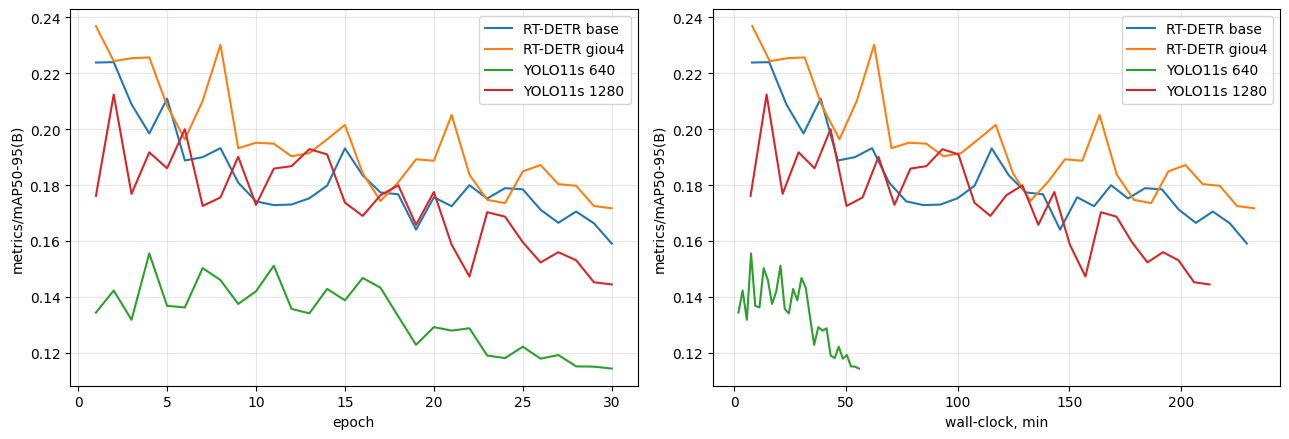

,run,epochs,best_epoch,best_mAP50-95,last_mAP50-95,minutes
0,af_baseline,30,4,0.1555,0.1143,55.8308
1,af_1280,30,2,0.2124,0.1444,212.7600
2,af_p2,30,14,0.1505,0.1174,95.5558
3,af_nwd,30,4,0.1574,0.1176,57.0460
4,af_box10,30,2,0.1575,0.1197,56.6390


In [15]:
# validation mAP over training: RT-DETR vs YOLO (epochs and wall-clock) + best epoch per run
import matplotlib.pyplot as plt

def plot_curves(curves, metric='metrics/mAP50-95(B)'):
    fig, ax = plt.subplots(1, 2, figsize=(13, 4.5))
    for label, path in curves.items():
        df = pd.read_csv(path); df.columns = [c.strip() for c in df.columns]
        ax[0].plot(df['epoch'], df[metric], label=label)
        if 'time' in df:
            ax[1].plot(df['time'] / 60, df[metric], label=label)
    ax[0].set_xlabel('epoch'); ax[1].set_xlabel('wall-clock, min')
    for a in ax:
        a.set_ylabel(metric); a.grid(alpha=.3); a.legend()
    fig.tight_layout(); fig.savefig(f'{RUNS}/val_map_curves.png', dpi=130); plt.show()

curves = {
    'RT-DETR base':  f'{RUNS}/rtdetr_base/results.csv',
    'RT-DETR giou4': f'{RUNS}/rtdetr_giou4/results.csv',
    'YOLO11s 640':   f'{AF_DIR}/af_baseline/results.csv',
    'YOLO11s 1280':  f'{AF_DIR}/af_1280/results.csv',
}
plot_curves(curves)

# best epoch table for the anchor-free runs
rows = []
for n in ['af_baseline', 'af_1280', 'af_p2', 'af_nwd', 'af_box10']:
    df = pd.read_csv(f'{AF_DIR}/{n}/results.csv'); df.columns = [c.strip() for c in df.columns]
    m = df['metrics/mAP50-95(B)']
    rows.append({'run': n, 'epochs': len(df), 'best_epoch': int(m.idxmax()) + 1,
                 'best_mAP50-95': m.max(), 'last_mAP50-95': m.iloc[-1], 'minutes': df['time'].iloc[-1] / 60})
pd.DataFrame(rows).round(4)

In [16]:
AF_RESULTS = json.load(open(f'{AF_DIR}/results_anchor_free.json'))
all_res = {**{k: v for k, v in RESULTS.items() if k.startswith('rtdetr')},
           **{f'yolo30_{k}': v for k, v in AF_RESULTS.items()}}
pd.DataFrame(all_res).T[['mAP', 'AP50', 'AP_small', 'AP_medium', 'AP_large', 'ms_per_img', 'imgsz']].round(4)

,mAP,AP50,AP_small,AP_medium,AP_large,ms_per_img,imgsz
rtdetr_base,0.2332,0.4690,0.1308,0.2188,0.3495,32.8658,640.0
rtdetr_nq100,0.2307,0.4339,0.1217,0.1940,0.4311,34.6081,640.0
rtdetr_giou4,0.2457,0.4621,0.1363,0.2208,0.4075,34.6226,640.0
rtdetr_lr1e-4,0.2229,0.4252,0.1182,0.2109,0.4114,34.6562,640.0
rtdetr_e8,0.1317,0.2569,0.0662,0.1259,0.2965,34.7231,640.0
rtdetr_frozen,0.0000,0.0000,0.0000,0.0000,0.0000,34.7688,640.0
yolo30_af_baseline,0.1380,0.2790,0.0779,0.1658,0.2940,7.2165,640.0
yolo30_af_1280,0.2188,0.4343,0.1238,0.2085,0.2908,29.9284,1280.0
yolo30_af_p2,0.1324,0.2768,0.0964,0.1490,0.2257,10.9679,640.0
yolo30_af_nwd,0.1448,0.2846,0.0745,0.1538,0.2678,7.2396,640.0


In [ ]:
# AP by scene density (terciles of objects per frame); sizes are in the AP_small/medium/large columns above
def ap_by_density(names):
    gt, _ = GT
    rows = {}
    for name in names:
        ids, dets = DETS[name]
        n = np.array([sum(1 for a in gt.imgToAnns[i] if not a['iscrowd']) for i in ids])
        edges = np.quantile(n, [0, .33, .66, 1])
        for k in range(3):
            lo, hi = edges[k], edges[k + 1]
            sel = [i for i, c in zip(ids, n) if c >= lo and (c <= hi if k == 2 else c < hi)]
            S = set(sel)
            rows[(name, f'{int(lo)}-{int(hi)} objects/frame')] = coco_eval(gt, [d for d in dets if d['image_id'] in S], sel)
    return pd.DataFrame(rows).T.round(4)

if GT is None: GT = build_val_gt()
evaluate('yolo30_baseline', f'{AF_DIR}/af_baseline/weights/best.pt', IMGSZ, model_cls=YOLO)
ap_by_density(['rtdetr_base', 'rtdetr_nq100', 'rtdetr_giou4', 'yolo30_baseline'])

## 6. Ensemble: Weighted Boxes Fusion of RT-DETR and YOLO
Settings of the submitted ensemble: best RT-DETR run, YOLO `af_box10`, weights [2, 1], IoU threshold 0.6.

In [ ]:
warnings.filterwarnings('ignore', message='Zero area box skipped')
import scripts.ensemble as ensm   

best = max((k for k in RESULTS if k.startswith('rtdetr')), key=lambda k: RESULTS[k]['mAP'])
RT_W = f'{RUNS}/{best}/weights/best.pt'
YOLO_W = 'runs/af_1280/weights/best.pt'
YOLO_IMGSZ = 1280
print('RT-DETR:', best, '| YOLO: af_1280')print('RT-DETR:', best, '| YOLO: af_box10')

if GT is None: GT = build_val_gt()
gt, id2path = GT
ids = sorted(id2path); paths = [id2path[i] for i in ids]
sizes = {id2path[i]: (gt.imgs[i]['width'], gt.imgs[i]['height']) for i in ids}
p_rt, _ = run_model(RT_W, paths, IMGSZ, RTDETR)
p_yo, _ = run_model(YOLO_W, paths, YOLO_IMGSZ, YOLO)

In [ ]:
# tune fusion weights / IoU threshold on every 5th validation frame (validation-only analysis)
sub = ids[::5]; sp = [id2path[i] for i in sub]
rows = [{'weights': 'RT-DETR alone', 'iou_thr': None, 'mAP': ensm.score(gt, id2path, p_rt, ids=sub)['mAP']},
        {'weights': 'YOLO alone', 'iou_thr': None, 'mAP': ensm.score(gt, id2path, p_yo, ids=sub)['mAP']}]
for w_ in ([1, 1], [2, 1], [3, 1]):
    for thr in (0.5, 0.6, 0.7, 0.8):
        e = ensm.wbf_preds([p_rt, p_yo], sizes, w_, thr, paths=sp)
        rows.append({'weights': str(w_), 'iou_thr': thr, 'mAP': ensm.score(gt, id2path, e, ids=sub)['mAP']})
pd.DataFrame(rows).round(4)

In [ ]:
# full validation with the settings of the submitted ensemble
W_BEST, THR_BEST = [2, 1], 0.6
e_val = ensm.wbf_preds([p_rt, p_yo], sizes, W_BEST, THR_BEST)
cols = ['mAP', 'AP50', 'AP75', 'AP_small', 'AP_medium', 'AP_large']
pd.DataFrame({'RT-DETR': RESULTS[best], 'YOLO af_1280': RESULTS['af_1280'],
              'WBF ensemble': ensm.score(gt, id2path, e_val)}).T[cols].round(4)

## 8. Submitted files

In [ ]:
def make_submission(weights, imgsz, out, model_cls=RTDETR, conf=0.001):
    df = pd.read_csv(f'{DATA_ROOT}/test_images.csv')
    paths = [f'{DATA_ROOT}/{f}' for f in df['file_name']]
    preds, ms = run_model(weights, paths, imgsz, model_cls, conf=conf)
    rows = []
    for iid, p in zip(df['image_id'], paths):
        xyxy, sc, cl = preds[p]
        s = ' '.join(f'{int(c)} {v:.4f} {int(x1)} {int(y1)} {int(x2 - x1)} {int(y2 - y1)}'
                     for (x1, y1, x2, y2), v, c in zip(xyxy, sc, cl))
        rows.append({'image_id': iid, 'PredictionString': s})
    pd.DataFrame(rows).to_csv(out, index=False)
    print('wrote', out, len(rows), 'rows', f'({ms:.1f} ms/img)')

MAKE_TEST_FILES = False
if MAKE_TEST_FILES:
    make_submission(RT_W, IMGSZ, '/kaggle/working/submission_rtdetr_2.csv')

    df = pd.read_csv(f'{DATA_ROOT}/test_images.csv')
    tpaths = [f'{DATA_ROOT}/{f}' for f in df['file_name']]
    tsizes = {p: (a, b) for p, a, b in zip(tpaths, df['width'], df['height'])}
    t_rt, _ = run_model(RT_W, tpaths, IMGSZ, RTDETR)
    t_yo, _ = run_model(YOLO_W, tpaths, YOLO_IMGSZ, YOLO)
    t_ens = ensm.wbf_preds([t_rt, t_yo], tsizes, W_BEST, THR_BEST, paths=tpaths)
    ensm.write_submission(t_ens, df, tpaths, '/kaggle/working/submission_ens.csv')